In [1]:
import numpy as np 
import xarray as xr
import matplotlib.pyplot as plt

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

import time
start_time = time.time()

In [2]:
%cd /emmy-noether/home/mf671/DATA/IFS
!ls

/emmy-noether/home/mf671/DATA/IFS
geop  gr_tracking


In [3]:
'''
data_dir='/emmy-noether/home/mf671/DATA/ERA5/geop/'
fn = data_dir + "ERA5_northem_2.5x2.5_zg500_daily_1940-2023.nc"
work_dic='/emmy-noether/home/mf671/DATA/ERA5/gr_tracking/'
fn_out_unfilt = work_dic + "ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc"
fn_out = work_dic + "ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc"
fn_dic_unfilt = work_dic + "dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023_DIC.npy"
fn_dic = work_dic + "dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_DIC.npy"
'''
data_dir='/emmy-noether/home/mf671/DATA/ERA5/geop/'
fn = data_dir + "ERA5_northem_2.5x2.5_zg500_daily_1960-1963.nc"
work_dic='/emmy-noether/home/mf671/DATA/ERA5/gr_tracking/'
fn_out_unfilt = work_dic + "ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1960-1963.nc"
fn_out = work_dic + "ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963.nc"
fn_dic_unfilt = work_dic + "dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1960-1963_DIC.npy"
fn_dic = work_dic + "dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963_DIC.npy"
#'''

In [4]:
print("Starting operation")
ds = xr.load_dataset(fn)
print("Data correctly read")
ds = BT.DAV(ds,mer_gradient_filter = True, tyrlis_correction=True,)
print(np.amax(ds['DAV_freq']))
print("DAV function correctly executed")
ds,dic_unfilt = BT.ContourTracking2D(ds,var_name = "DAV",max_dist = 1000)
#saving temporary data
ds.to_netcdf(fn_out_unfilt)
np.save(fn_dic_unfilt,dic_unfilt)

Starting operation
Data correctly read
__Starting a DAV process__
input: zg500 , mer_gradient_filter = True, tyrlis_correction = True
<xarray.DataArray 'DAV_freq' ()> Size: 8B
array(25.11978097)
DAV function correctly executed
__Starting a Tracking process__
input: DAV
connected component analysis


100%|██████████████████████████████████████████████████████████████████| 1461/1461 [00:02<00:00, 597.21it/s]


rearranging indexes


100%|█████████████████████████████████████████████████████████████████| 1461/1461 [00:00<00:00, 2259.65it/s]


calculating characteristics
persistence, track, date:


100%|██████████████████████████████████████████████████████████████████| 1461/1461 [00:06<00:00, 234.43it/s]


area and intensity


100%|███████████████████████████████████████████████████████████████████| 1461/1461 [00:51<00:00, 28.23it/s]


number of labels: 4483.0


In [5]:
from importlib import reload
reload(BT)
ds = xr.load_dataset(fn_out_unfilt)
dic_unfilt = np.load(fn_dic_unfilt,allow_pickle=True)
ds2,dic_filt = BT.FilterEvents(ds,dic_unfilt,var_name = "DAV",
                              pers_min = 3,min_avg_area = 5e5)
print("ContourTracking2D function correclty executed")

__Starting a Filtering process__
input: DAV_tracked
applying filters


100%|████████████████████████████████████████████████████████████████| 4483/4483 [00:00<00:00, 46393.53it/s]


rearranging indexes


100%|█████████████████████████████████████████████████████████████████| 1461/1461 [00:00<00:00, 8752.15it/s]


number of labels: 614
ContourTracking2D function correclty executed


In [6]:
#saving data
np.save(fn_dic,dic_filt)
ds2.to_netcdf(fn_out)
print("Data created")
  
print("--- %s seconds ---" % (time.time() - start_time))

Data created
--- 66.39537715911865 seconds ---


In [7]:
distances = []
for event in dic_filt[1:]:
    for t in range(event['persistence']-1):
        distances.append(event['distance_traveled'][t])
        if event['distance_traveled'][t] > 2000:
            print(event)

(array([279., 556., 559., 374., 261., 128.,  80.,  60.,  57.,  37.]),
 array([  0.        ,  99.6140567 , 199.22811341, 298.84217011,
        398.45622681, 498.07028352, 597.68434022, 697.29839693,
        796.91245363, 896.52651033, 996.14056704]),
 <BarContainer object of 10 artists>)

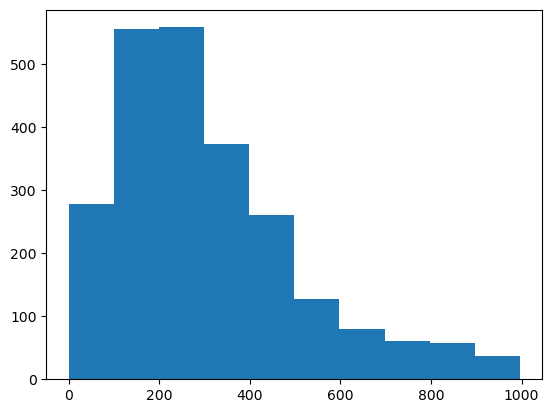

In [8]:
plt.hist(distances)

In [9]:
print(np.amax(distances))

996.140567035992
